# 02 — Baseline Model: TF-IDF and Logistic Regression

## Overview

This notebook develops a traditional machine learning baseline for AG News text classification.

The model uses TF-IDF to convert news articles into numerical features and Logistic Regression to predict one of four news categories.

The baseline provides a reference point for evaluating the performance of a fine-tuned Transformer model.

## Objectives

- Load and prepare the AG News dataset.
- Create training, validation, and test splits.
- Convert text into numerical features using TF-IDF.
- Train a Logistic Regression classifier.
- Evaluate classification performance.
- Investigate misclassified articles and model coefficients.
- Save and reload the trained model and vectorizer.

## News Categories

The dataset contains four categories: World, Sports, Business, and Sci/Tech.

## 1. Loading the Project and Dataset

We load the AG News dataset using the project's reusable data-loading utility.

Keeping data-loading logic in a separate module helps maintain consistency across notebooks and other components of the project.

We inspect the available dataset splits and their structure before preparing the data for training.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()

if not (PROJECT_ROOT / "src" / "data_loader.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src" / "data_loader.py").exists():
    raise FileNotFoundError(
        "Cannot find project root containing src/data_loader.py. "
        "Run this notebook from the project root or notebooks directory."
    )

os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_ag_news

print("Project path:", PROJECT_ROOT)
print("Data loader imported successfully!")

Project path: /mnt/d809bc61-ebac-4ca7-8e1e-e0a6d7e8f201/Documents/Programming/MyProjects/transformer-news-classification
Data loader imported successfully!


In [2]:
from src.data_loader import load_ag_news

dataset = load_ag_news()

print("Available dataset splits:", list(dataset.keys()))

Available dataset splits: ['train', 'test']


In [3]:
print("Available dataset splits:", list(dataset.keys()))
print("Test columns:", dataset["test"].column_names)

Available dataset splits: ['train', 'test']
Test columns: ['text', 'label']


## 2. Creating Training and Validation Sets

The original training split is divided into two subsets:

- **Training set:** Used to fit the model.
- **Validation set:** Used to evaluate model performance during development.

We reserve 10% of the original training data for validation.

Stratified splitting preserves the approximate class proportions in both subsets. The fixed random seed makes the split reproducible.

The official test set remains separate and is reserved for the final model evaluation.


In [4]:
from sklearn.model_selection import train_test_split

train_texts, val_texts, train_labels, val_labels = train_test_split(
    dataset["train"]["text"],
    dataset["train"]["label"],
    test_size=0.1,
    random_state=42,
    stratify=dataset["train"]["label"],
)

test_texts = dataset["test"]["text"]
test_labels = dataset["test"]["label"]

print("Train:", len(train_texts))
print("Validation:", len(val_texts))
print("Test:", len(test_texts))

Train: 108000
Validation: 12000
Test: 7600


## 3. Text Representation with TF-IDF

Machine learning models generally require numerical input rather than raw text.

TF-IDF (Term Frequency–Inverse Document Frequency) represents a document using numerical weights associated with its terms.

- **Term Frequency (TF):** Measures how frequently a term appears in a document.
- **Inverse Document Frequency (IDF):** Reduces the importance of terms that appear across many documents.

The resulting representation gives greater weight to terms that are relatively informative within a document.

We fit the vectorizer on the training texts only, then use the fitted vectorizer to transform the validation and test texts. This prevents information from the evaluation sets from influencing the vocabulary and IDF statistics.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()

X_train = vectorizer.fit_transform(train_texts)
X_val = vectorizer.transform(val_texts)
X_test = vectorizer.transform(test_texts)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (108000, 62580)
X_val shape: (12000, 62580)
X_test shape: (7600, 62580)


## 4. Inspecting TF-IDF Features

After vectorization, each article is represented by a numerical feature vector.

We inspect the vocabulary and the number of generated features to understand how the text has been represented.

We also examine an example article, its analyzed tokens, and the corresponding TF-IDF vector.

Because text vectors are typically sparse, most entries are zero. The non-zero values indicate the terms that contribute to the representation of a particular article.

In [6]:
feature_names = vectorizer.get_feature_names_out()

print("Number of features:", len(feature_names))
print("First 20 features:")
print(feature_names[:20])

Number of features: 62580
First 20 features:
['00' '000' '000016447' '00010563n' '0002' '0004287' '0005173miami050'
 '000660' '0009875buffalo040' '000bn' '000km' '000m' '000metres' '000mph'
 '000rpm' '000th' '001' '001107539' '001273145' '0013']


In [7]:
sample_text = train_texts[0]

print(sample_text)

10 seconds that change everything ATHENS - Ten seconds. Barely time enough to tie a shoe, wash a glass, get the paper off the porch. But when the moment comes, and eight men kneel at their blocks and peer down the empty, waiting track, it is as if the entire Olympics stop to watch.


In [8]:
analyzer = vectorizer.build_analyzer()

tokens = analyzer(sample_text)

print("Number of tokens:", len(tokens))
print("First 30 tokens:")
print(tokens[:30])

Number of tokens: 51
First 30 tokens:
['10', 'seconds', 'that', 'change', 'everything', 'athens', 'ten', 'seconds', 'barely', 'time', 'enough', 'to', 'tie', 'shoe', 'wash', 'glass', 'get', 'the', 'paper', 'off', 'the', 'porch', 'but', 'when', 'the', 'moment', 'comes', 'and', 'eight', 'men']


In [9]:
sample_vector = X_train[0]

print("Vector shape:", sample_vector.shape)
print("Non-zero values:", sample_vector.nnz)

Vector shape: (1, 62580)
Non-zero values: 44


In [10]:
sample_vector = X_train[0]

nonzero_indices = sample_vector.nonzero()[1]
nonzero_values = sample_vector.data

for index, value in zip(nonzero_indices, nonzero_values):
    print(feature_names[index], "->", value)

10 -> 0.10693011663352177
seconds -> 0.3137824017133507
that -> 0.0591349035356485
change -> 0.13594572381417586
everything -> 0.1669169105270274
athens -> 0.1259470574680866
ten -> 0.1592939791817941
barely -> 0.17631024706109943
time -> 0.09625473146997487
enough -> 0.13971232080826954
to -> 0.0685338171665564
tie -> 0.15761549854720794
shoe -> 0.2044285551603092
wash -> 0.18874743265271654
glass -> 0.19346400533568942
get -> 0.11383157484644604
the -> 0.13916646974836477
paper -> 0.1669169105270274
off -> 0.1002455893661617
porch -> 0.24206383678327495
but -> 0.08332977335417818
when -> 0.09677823946181348
moment -> 0.1687511744961266
comes -> 0.14623662567599033
and -> 0.08339163020171499
eight -> 0.13104904852404503
men -> 0.12790706704733265
kneel -> 0.2739912611194033
at -> 0.06321559309274045
their -> 0.08146317444794667
blocks -> 0.18389436538789225
peer -> 0.17533697118160152
down -> 0.10584798857738226
empty -> 0.19146006646589953
waiting -> 0.16481218038748954
track -> 0.14

## 5. Training the Logistic Regression Classifier

Logistic Regression is a widely used classification algorithm that can serve as a strong baseline for text classification.

In this experiment, the classifier learns relationships between TF-IDF features and the four news categories.

The model is fitted using the training feature matrix and its corresponding labels.

After training, we generate predictions for the validation set to assess how well the model generalizes to unseen articles.

In [11]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, train_labels)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [12]:
val_predictions = model.predict(X_val)

print("Number of predictions:", len(val_predictions))
print("First 20 predictions:", val_predictions[:20])
print("First 20 actual labels:", val_labels[:20])

Number of predictions: 12000
First 20 predictions: [3 3 0 2 1 0 3 0 2 0 1 1 1 1 2 3 2 1 0 2]
First 20 actual labels: [3, 3, 0, 2, 2, 0, 3, 0, 2, 0, 1, 0, 1, 1, 2, 3, 2, 1, 0, 2]


## 6. Evaluating Classification Performance

We evaluate the model using several classification metrics.

- **Accuracy:** The proportion of correctly classified articles.
- **Precision:** The proportion of predictions for a class that are correct.
- **Recall:** The proportion of actual examples of a class that are correctly identified.
- **F1-score:** The harmonic mean of precision and recall.

The classification report provides per-class results as well as macro-averaged metrics.

Using multiple metrics gives a more complete picture of model performance than accuracy alone.

In [13]:
from sklearn.metrics import accuracy_score

val_accuracy = accuracy_score(val_labels, val_predictions)

print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Accuracy (%): {val_accuracy * 100:.2f}%")

Validation Accuracy: 0.9213
Validation Accuracy (%): 92.12%


In [14]:
from sklearn.metrics import classification_report

print(
    classification_report(
        val_labels,
        val_predictions,
        target_names=["World", "Sports", "Business", "Sci/Tech"],
        digits=4
    )
)

              precision    recall  f1-score   support

       World     0.9290    0.9067    0.9177      3000
      Sports     0.9512    0.9817    0.9662      3000
    Business     0.8987    0.8843    0.8915      3000
    Sci/Tech     0.9051    0.9123    0.9087      3000

    accuracy                         0.9213     12000
   macro avg     0.9210    0.9212    0.9210     12000
weighted avg     0.9210    0.9213    0.9210     12000



### Confusion Matrix

The confusion matrix compares the actual categories with the categories predicted by the model.

Correct predictions appear along the main diagonal, while off-diagonal entries represent classification errors.

This view helps identify which news categories the model confuses most frequently.

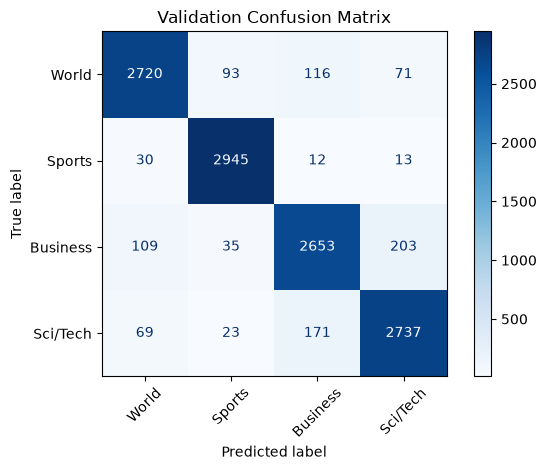

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(val_labels, val_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["World", "Sports", "Business", "Sci/Tech"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Validation Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Error Analysis

Evaluating aggregate metrics does not explain why individual predictions are incorrect.

We therefore inspect misclassified validation examples and compare their actual and predicted categories.

Reading these examples can reveal ambiguous articles, overlapping vocabulary, or other patterns that make classification difficult.

This analysis helps us understand the limitations of the baseline and identify opportunities for improvement.

In [16]:
import numpy as np

wrong_indices = np.where(val_labels != val_predictions)[0]

print("Total incorrect predictions:", len(wrong_indices))

Total incorrect predictions: 945


In [17]:
label_names = ["World", "Sports", "Business", "Sci/Tech"]

for index in wrong_indices[:3]:
    print("Actual category:", label_names[val_labels[index]])
    print("Predicted category:", label_names[val_predictions[index]])
    print("News text:", val_texts[index])
    print("-" * 80)

Actual category: Business
Predicted category: Sports
News text: Were You Ready for Some Football? Disney kicks off another season of Monday Night Football -- on a Thursday.
--------------------------------------------------------------------------------
Actual category: World
Predicted category: Sports
News text: Boston Beats Yanks 5-4 in 14 Innings BOSTON - Just like the game that seemed it would never end, Boston's season just won't end. David Ortiz's RBI single on the 471st pitch of the game with two outs in the 14th inning capped a second straight amazing comeback in less than 24 hours Monday night and gave the Red Sox a 5-4 victory over the New York Yankees in the AL championship series...
--------------------------------------------------------------------------------
Actual category: Sci/Tech
Predicted category: World
News text: Office Workers, Move Over: Here Comes Honda's Asimo  WAKO, Japan (Reuters) - Honda Motor Co.'s humanoid robot  has been around: he's rung the famed bell

## 8. Understanding Model Decisions

Logistic Regression learns coefficients that describe how input features contribute to its classification decisions.

We inspect the decision scores for a misclassified article to understand how the model scores the possible categories.

We then examine selected feature coefficients and investigate how individual words influence class scores.

These coefficients provide an interpretable view of the model's learned relationships between vocabulary and news categories.

In [18]:
sample_index = wrong_indices[0]

sample_text = val_texts[sample_index]

sample_vector = vectorizer.transform([sample_text])

scores = model.decision_function(sample_vector)

for class_name, score in zip(label_names, scores[0]):
    print(f"{class_name}: {score:.4f}")

World: -0.8574
Sports: 3.7243
Business: -0.7053
Sci/Tech: -2.1615


In [19]:
print("Coefficient matrix shape:", model.coef_.shape)
print("Class labels:", model.classes_)

Coefficient matrix shape: (4, 62580)
Class labels: [0 1 2 3]


### Word-Level Contributions

We examine how the TF-IDF values of individual words interact with the learned model coefficients.

This analysis identifies words that contribute positively or negatively to selected class scores for a particular article.

These contributions help explain part of the model's decision, although they should not be interpreted as proof of causation or as a complete explanation of the prediction.

In [20]:
words_to_check = ["football", "disney", "season", "monday", "night"]

for word in words_to_check:
    word_index = np.where(feature_names == word)[0]

    if len(word_index) == 0:
        print(f"{word}: Not found in vocabulary")
        continue

    index = word_index[0]

    print(f"\nWord: {word}")

    for class_index, class_name in enumerate(label_names):
        weight = model.coef_[class_index, index]
        print(f"  {class_name}: {weight:.4f}")


Word: football
  World: 0.3842
  Sports: 3.7681
  Business: -2.2445
  Sci/Tech: -1.9078

Word: disney
  World: -1.4140
  Sports: -1.3536
  Business: 2.7536
  Sci/Tech: 0.0140

Word: season
  World: -2.1240
  Sports: 4.6205
  Business: -0.4290
  Sci/Tech: -2.0676

Word: monday
  World: 0.6007
  Sports: 1.0698
  Business: 0.3240
  Sci/Tech: -1.9945

Word: night
  World: 1.0016
  Sports: 3.0910
  Business: -1.9064
  Sci/Tech: -2.1861


In [21]:
sample_index = wrong_indices[0]

sample_text = val_texts[sample_index]
sample_vector = vectorizer.transform([sample_text])

feature_indices = sample_vector.indices
tfidf_values = sample_vector.data

sports_contributions = (
    tfidf_values * model.coef_[1, feature_indices]
)

business_contributions = (
    tfidf_values * model.coef_[2, feature_indices]
)

print("Top contributions toward Sports:")

sports_order = np.argsort(sports_contributions)[::-1]

for position in sports_order[:10]:
    word = feature_names[feature_indices[position]]
    contribution = sports_contributions[position]
    print(f"{word:15s} {contribution:+.4f}")

print("\nTop contributions toward Business:")

business_order = np.argsort(business_contributions)[::-1]

for position in business_order[:10]:
    word = feature_names[feature_indices[position]]
    contribution = business_contributions[position]
    print(f"{word:15s} {contribution:+.4f}")

Top contributions toward Sports:
football        +1.9156
season          +0.9697
night           +0.6453
thursday        +0.2216
were            +0.1982
monday          +0.1902
kicks           +0.1226
another         +0.1206
you             +0.0948
ready           +0.0893

Top contributions toward Business:
disney          +0.8932
you             +0.1931
some            +0.0715
monday          +0.0576
off             +0.0404
kicks           +0.0157
on              +0.0069
of              +0.0056
for             -0.0226
ready           -0.0401


In [22]:
sports_negative_order = np.argsort(sports_contributions)

print("Lowest contributions toward Sports:")

for position in sports_negative_order[:10]:
    word = feature_names[feature_indices[position]]
    contribution = sports_contributions[position]
    print(f"{word:15s} {contribution:+.4f}")

Lowest contributions toward Sports:
disney          -0.4391
some            -0.1924
of              -0.1465
off             +0.0233
on              +0.0369
for             +0.0416
ready           +0.0893
you             +0.0948
another         +0.1206
kicks           +0.1226


In [23]:
sample_index = wrong_indices[0]

sample_vector = vectorizer.transform(
    [val_texts[sample_index]]
)

feature_indices = sample_vector.indices
tfidf_values = sample_vector.data

sports_contributions = (
    tfidf_values * model.coef_[1, feature_indices]
)

total_contribution = sports_contributions.sum()
sports_bias = model.intercept_[1]

calculated_score = total_contribution + sports_bias

actual_score = model.decision_function(sample_vector)[0, 1]

print("Sum of word contributions:", total_contribution)
print("Sports bias:", sports_bias)
print("Calculated score:", calculated_score)
print("Actual model score:", actual_score)

Sum of word contributions: 3.8915335261261172
Sports bias: -0.167271621609787
Calculated score: 3.72426190451633
Actual model score: 3.7242619045163305


In [24]:
probabilities = model.predict_proba(sample_vector)

for class_name, probability in zip(label_names, probabilities[0]):
    print(f"{class_name}: {probability:.4f}")

World: 0.0100
Sports: 0.9757
Business: 0.0116
Sci/Tech: 0.0027


## 9. Saving the Trained Artifacts

A trained classifier depends on both the model and the text preprocessing component used during training.

We save the Logistic Regression model and the fitted TF-IDF vectorizer using Joblib.

Both artifacts are required for consistent inference: incoming text must be transformed using the same vectorizer before being passed to the classifier.

In [25]:
import joblib
from pathlib import Path

# The current working directory is the project root
PROJECT_ROOT = Path.cwd()
MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(vectorizer, MODELS_DIR / "tfidf_vectorizer.joblib")
joblib.dump(model, MODELS_DIR / "logistic_regression.joblib")

print("Vectorizer and model saved successfully.")
print("Models directory:", MODELS_DIR.resolve())

Vectorizer and model saved successfully.
Models directory: /mnt/d809bc61-ebac-4ca7-8e1e-e0a6d7e8f201/Documents/Programming/MyProjects/transformer-news-classification/models


### Verifying the Saved Artifacts

We reload the saved model and vectorizer and use them to classify a new example.

This test checks that the saved artifacts can be loaded and used for inference independently of the original training objects.

The same preprocessing component must be used during training and deployment to maintain consistent input features.

In [26]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path.cwd()
MODELS_DIR = PROJECT_ROOT / "models"

loaded_vectorizer = joblib.load(MODELS_DIR / "tfidf_vectorizer.joblib")
loaded_model = joblib.load(MODELS_DIR / "logistic_regression.joblib")

sample_text = "The football team won the championship."
sample_vector = loaded_vectorizer.transform([sample_text])
prediction = loaded_model.predict(sample_vector)

label_names = ["World", "Sports", "Business", "Sci/Tech"]

print("Predicted category:", label_names[prediction[0]])
print("Models directory:", MODELS_DIR.resolve())

Predicted category: Sports
Models directory: /mnt/d809bc61-ebac-4ca7-8e1e-e0a6d7e8f201/Documents/Programming/MyProjects/transformer-news-classification/models


##  Conclusion

In this notebook, we established a baseline model for the AG News text classification task using TF-IDF feature extraction and Logistic Regression.

The original training set was divided into training and validation subsets using stratified sampling, while the official test set was kept separate for final evaluation.

The baseline achieved approximately 92.13% accuracy on the validation set. We also examined the classification report, confusion matrix, misclassified examples, and word-level contributions to understand the model's behavior.

Finally, we saved the trained TF-IDF vectorizer and Logistic Regression model so they can be loaded and reused without retraining.

### Key Takeaways

- TF-IDF converts news articles into numerical features.
- Logistic Regression uses these features to predict news categories.
- Error analysis helps identify patterns behind incorrect predictions.
- The baseline provides a reference point for comparison with the Transformer model.

### Limitations

TF-IDF represents text using word-based features and does not fully capture word order or contextual meaning. A Transformer-based model may learn richer contextual representations.

The final comparison with the Transformer model will be performed in the model comparison notebook.